# 02 - Prediction model: OLS significance test, SDV enrichment and NNLS

Computes the OLS significance test (Table III: $P$- and $t$-values), the NNLS parameters $\tilde\theta$ of Eq. (10) and the predicted vs actual safety / comfort on the 4 test cities (Fig. 6).

Pipeline (Fig. 4 of the paper):
1. OLS on the 14 cities with $[1, s_\mathcal{G}, c_\mathcal{G}, l_\mathcal{G}]$ -> only $l_\mathcal{G}$ is significant.
2. Split: 10 training cities / 4 test cities (Annecy, Bordeaux, Chambery, Dunkerque).
3. Enrich the training set with 990 synthetic samples from the Synthetic Data Vault (SDV, Gaussian copula).
4. Non-negative least squares on the enriched training set -> $\tilde\theta$.
5. Compare with an AutoGluon (Auto-ML) ensemble on the test cities.

The synthetic samples of the 2024 run are stored in `data/model/sdv_synthetic_*.csv`. SDV sampling is random, so set `REGENERATE_SDV = True` to draw new ones (results will vary slightly - this is expected).

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # the cycling_tits package

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from cycling_tits import CITIES, FIGURES, RESULTS, load_network, load_survey, pretty, Model, alphas
FIGURES.mkdir(exist_ok=True)

In [2]:
import statsmodels.api as sm
metrics = pd.read_csv(RESULTS / "metrics_cities.csv", index_col="city")   # from notebook 01
survey = load_survey()
df = metrics[["s_G", "c_G", "l_G"]].join(survey)   # full precision (as in the original regression)
df

,s_G,c_G,l_G,y_safety,y_comfort,split
city,,,,,,
Angers,0.441987,0.357481,0.111289,0.420,0.484,train
Annecy,0.346921,0.288683,0.054335,0.448,0.552,test
Bordeaux,0.423265,0.387958,0.065257,0.440,0.458,test
Chambery,0.393947,0.329095,0.172866,0.514,0.564,test
Dunkerque,0.456512,0.504900,0.086952,0.488,0.524,test
Grenoble,0.416956,0.426304,0.202789,0.608,0.674,train
La_Rochelle,0.355654,0.427456,0.152919,0.566,0.608,train
Le_Havre,0.550382,0.496296,0.120851,0.458,0.444,train
Lyon,0.345344,0.407790,0.166468,0.440,0.508,train


## Table III - OLS regression on the 14 cities

In [3]:
rows = []
for target in ["safety", "comfort"]:
    res = sm.OLS(df[f"y_{target}"], sm.add_constant(df[["s_G", "c_G", "l_G"]])).fit()
    for name in ["const", "s_G", "c_G", "l_G"]:
        rows.append(dict(target=target, predictor=name.replace("const", "Intercept"),
                         coefficient=res.params[name], abs_t=abs(res.tvalues[name]), p_value=res.pvalues[name]))
table3 = pd.DataFrame(rows).set_index(["target", "predictor"]).round(4)
table3

coefficient   abs_t  p_value
target  predictor                              
safety  Intercept       0.4255  4.8159   0.0007
        s_G            -0.0063  0.0261   0.9797
        c_G            -0.0330  0.1730   0.8661
        l_G             0.6149  3.3404   0.0075
comfort Intercept       0.5940  5.9804   0.0001
        s_G            -0.2311  0.8480   0.4163
        c_G            -0.1316  0.6137   0.5531
        l_G             0.7112  3.4366   0.0064

In [4]:
from scipy import stats
print("critical |t| for alpha = 0.05, df = 10:", round(stats.t.ppf(0.975, 10), 3))
print("significant predictors:", table3[table3.p_value < 0.05].index.tolist())

critical |t| for alpha = 0.05, df = 10: 2.228
significant predictors: [('safety', 'Intercept'), ('safety', 'l_G'), ('comfort', 'Intercept'), ('comfort', 'l_G')]


## Synthetic Data Vault enrichment of the training set

In [5]:
REGENERATE_SDV = False      # True: draw new synthetic samples (needs the `sdv` package)
N_SYNTHETIC = 1000           # 10 real + 1000 synthetic training rows (as in the 2024 run)

train = df[df.split == "train"]
test = df[df.split == "test"]
cols = ["s_G", "l_G", "c_G"]

synthetic = {}
for target in ["safety", "comfort"]:
    real = train[cols + [f"y_{target}"]]
    if REGENERATE_SDV:
        from sdv.metadata import SingleTableMetadata
        from sdv.single_table import GaussianCopulaSynthesizer
        meta = SingleTableMetadata(); meta.detect_from_dataframe(real)
        synth = GaussianCopulaSynthesizer(meta); synth.fit(real)
        synthetic[target] = synth.sample(N_SYNTHETIC)
    else:
        synthetic[target] = pd.read_csv(RESULTS.parent / "data" / "model" / f"sdv_synthetic_{target}.csv").iloc[:N_SYNTHETIC]
    print(target, "synthetic rows:", len(synthetic[target]))
synthetic["safety"].describe().round(3)

safety synthetic rows: 1000
comfort synthetic rows: 1000


,s_G,l_G,c_G,y_safety
count,1000.000,1000.000,1000.000,1000.000
mean,0.415,0.140,0.428,0.493
std,0.059,0.081,0.077,0.063
min,0.345,0.043,0.321,0.412
25%,0.358,0.067,0.367,0.436
50%,0.407,0.131,0.422,0.488
75%,0.458,0.192,0.477,0.541
max,0.550,0.376,0.609,0.622


## NNLS on the enriched training set -> $\tilde\theta$ (Eq. 10)
The original code fitted `LinearRegression(positive=True)` (= NNLS with a free intercept) on $[s_\mathcal{G}, l_\mathcal{G}, c_\mathcal{G}]$; the positivity constraint drives the coefficients of $s_\mathcal{G}$ and $c_\mathcal{G}$ to 0, leaving $y = \theta_0 + \theta_1 l_\mathcal{G}$.

In [6]:
from sklearn.linear_model import LinearRegression
theta, pred = {}, {}
for target in ["safety", "comfort"]:
    y = f"y_{target}"
    data = pd.concat([train[cols + [y]], synthetic[target]], ignore_index=True)
    reg = LinearRegression(positive=True).fit(data[cols], data[y])
    theta[target] = dict(intercept=reg.intercept_, **dict(zip(cols, reg.coef_)))
    pred[target] = reg.predict(test[cols])
pd.DataFrame(theta).T.round(4)

,intercept,s_G,l_G,c_G
safety,0.4116,0.0,0.5813,0.0
comfort,0.4569,0.0,0.5794,0.0


In [7]:
th = [theta["safety"]["intercept"], theta["safety"]["l_G"], theta["comfort"]["intercept"], theta["comfort"]["l_G"]]
print("theta_tilde              :", np.round(th, 5))
print("truncated to 2 decimals  :", np.floor(np.array(th) * 100) / 100, " (values used by the preset 'cscs')")

theta_tilde              : [0.41158 0.58127 0.45689 0.57944]
truncated to 2 decimals  : [0.41 0.58 0.45 0.57]  (values used by the preset 'cscs')


## Fig. 6 - predictions on the 4 test cities
The AutoGluon predictions were produced in a separate (Colab) session; their values are stored in `data/model/automl_predictions.csv`. An optional cell at the end re-runs AutoGluon if it is installed (it is *not* part of `environment.yml`: heavy and conflicts with pygmo).

safety   mean abs. % error  NNLS: 2.23 %   Auto-ML: 3.16 %


comfort  mean abs. % error  NNLS: 5.99 %   Auto-ML: 7.37 %


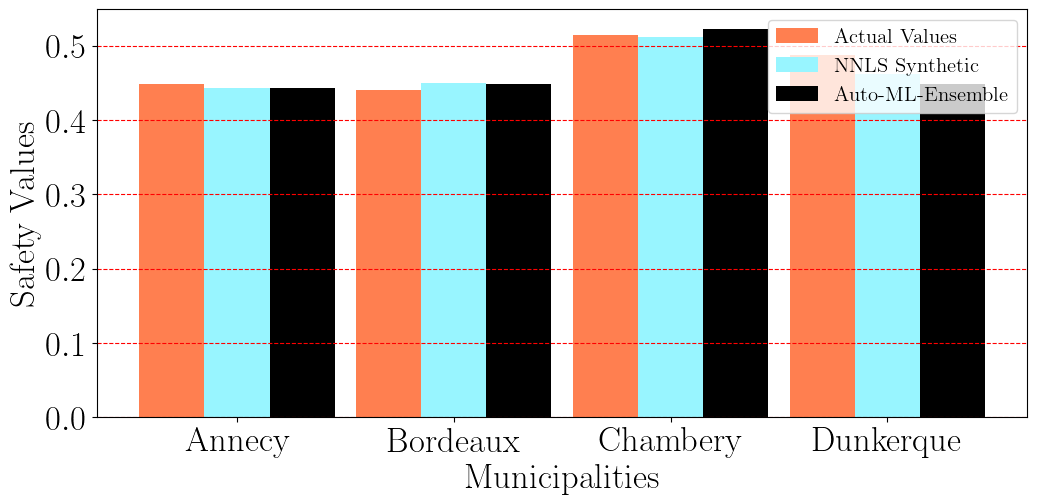

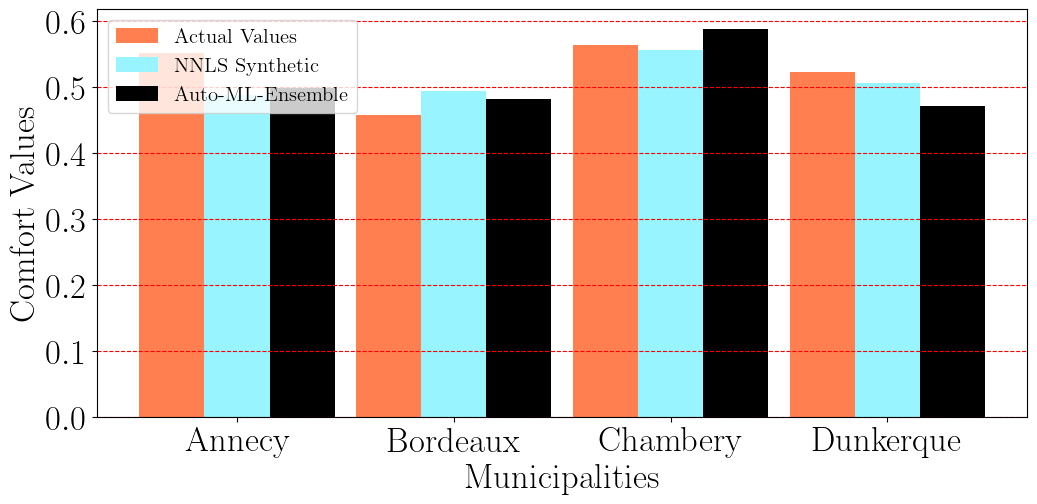

In [8]:
from cycling_tits.plotting import prediction_bars
automl = pd.read_csv(RESULTS.parent / "data" / "model" / "automl_predictions.csv", index_col="city").loc[test.index]
mape = lambda a, b: float(np.mean(100 * np.abs(np.asarray(a) - np.asarray(b)) / np.asarray(a)))
for target in ["safety", "comfort"]:
    actual = test[f"y_{target}"].values
    print(f"{target:8s} mean abs. % error  NNLS: {mape(actual, pred[target]):.2f} %   Auto-ML: {mape(actual, automl[target]):.2f} %")
    prediction_bars(list(test.index), actual, pred[target], automl[target].values,
                    target.capitalize(), outfile=FIGURES / f"{target}_prediction.png")

In [9]:
# Optional: re-run the Auto-ML ensemble (requires `pip install autogluon.tabular` in a separate env)
RUN_AUTOGLUON = False
if RUN_AUTOGLUON:
    from autogluon.tabular import TabularPredictor
    for target in ["safety", "comfort"]:
        y = f"y_{target}"
        data = pd.concat([train[cols + [y]], synthetic[target]], ignore_index=True)
        p = TabularPredictor(label=y, problem_type="regression", verbosity=0).fit(data, presets="best_quality")
        print(target, p.predict(test[cols]).round(4).to_dict())